# Results Plots

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import camb

pars = camb.CAMBparams()

In [3]:
data = np.load("results/f60_noise90only.npz")

noises = data["noises"]
sigma = data["sigma"]
bias = data["bias"]
ell_bins = data["ell_bins"]
cl_mean = data["cl_mean"]
cl_std = data["cl_std"]

In [4]:
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

goal_low = goal[goal['noise'] <= 100]

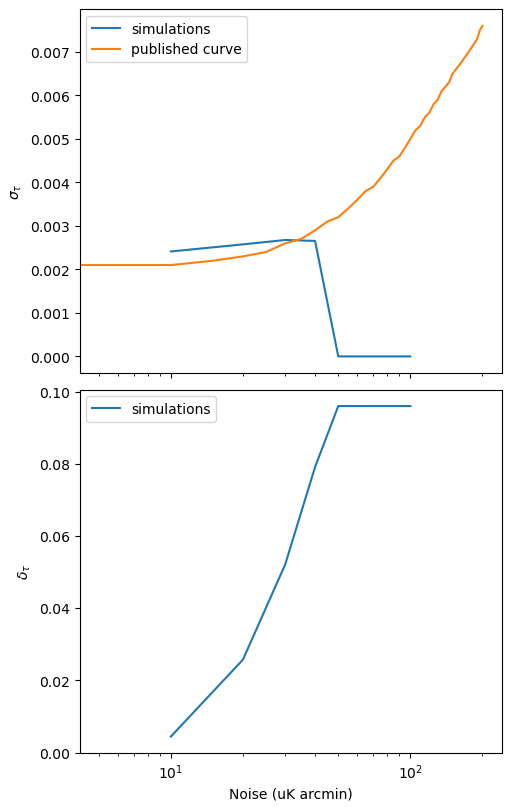

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(5,8), sharex=True, constrained_layout=True)
ax[0].semilogx(noises[1:], sigma[1:], label='simulations')
ax[0].semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
ax[0].set_ylabel(r'$\sigma_{\tau}$')
ax[0].legend()
ax[1].semilogx(noises[1:], bias[1:], label='simulations')
ax[1].set_ylabel(r'$\delta_{\tau}$')
ax[1].set_xlabel("Noise (uK arcmin)")
ax[1].legend()

In [21]:
lmax_sim = 32

In [25]:
def get_Clhat(tau, lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls_sim = np.arange(2, lmax_sim+1)
true_spectra_sim = get_Clhat(true_tau, lmax=lmax_sim) # ensemble average power spectrum for higher resolution maps

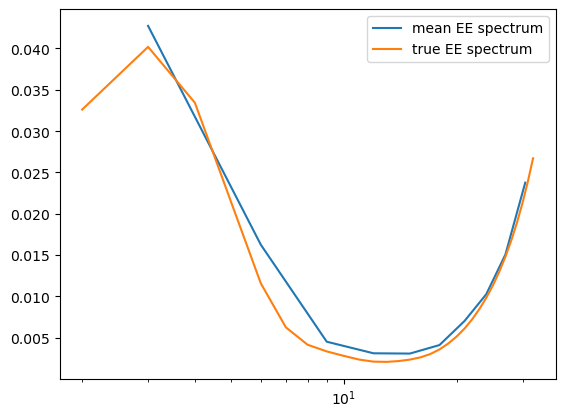

In [38]:
Z = ell_bins*(ell_bins+1)/(2*np.pi)
plt.semilogx(ell_bins, cl_mean[1]*Z, label='mean EE spectrum')
# plt.semilogx(ell_bins, cl_mean[5] + cl_std[5], label='mean + 1 std')
# plt.semilogx(ell_bins, cl_mean[5] - cl_std[5], label='mean - 1 std')
Z = ls_sim*(ls_sim+1)/(2*np.pi)
plt.semilogx(ls_sim, true_spectra_sim[1][ls_sim]*Z, label='true EE spectrum')
plt.legend()